<a href="https://colab.research.google.com/github/tvml/ml2627/blob/master/codici/linregr_samples.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressione lineare bayesiana: posterior dei parametri e campionamento di modelli

Questo notebook riproduce l'esempio dell'**aggiornamento sequenziale** delle note: un modello lineare con due parametri, $h(x)=w_0+w_1x$, il cui posterior viene visualizzato nel piano $(w_0,w_1)$ man mano che aumenta il numero di elementi osservati, insieme ad alcune rette campionate da esso.

## Richiami

Nell'approccio bayesiano i parametri sono variabili casuali. Il **prior** $p(\mathbf{w})=\mathcal{N}(\mathbf{0},\boldsymbol\Sigma_0)$ esprime ciò che si crede dei parametri prima di osservare i dati; la **verosimiglianza**, con rumore gaussiano di precisione $\beta$, è $p(\mathbf{t}\mid\mathbf{X},\mathbf{w})=\prod_i\mathcal{N}(t_i\mid\mathbf{w}^T\boldsymbol\phi(x_i),\beta^{-1})$. Per la regola di Bayes il **posterior** è proporzionale al loro prodotto, ed è ancora gaussiano:
$$\boldsymbol\Sigma_p=\bigl(\boldsymbol\Sigma_0^{-1}+\beta\boldsymbol\Phi^T\boldsymbol\Phi\bigr)^{-1},\qquad \mathbf{m}_p=\beta\,\boldsymbol\Sigma_p\boldsymbol\Phi^T\mathbf{t}.$$
La **precisione** del posterior (l'inversa della covarianza) è la somma della precisione del prior e di quella portata dai dati, $\beta\boldsymbol\Phi^T\boldsymbol\Phi$, che cresce con ogni nuovo elemento: il posterior si concentra sempre di più. Con il prior isotropo $\boldsymbol\Sigma_0=\alpha^{-1}\mathbf{I}$ delle note, $\boldsymbol\Sigma_0^{-1}=\alpha\mathbf{I}$.

Ogni punto del piano $(w_0,w_1)$ corrisponde a una retta: campionare parametri dal posterior significa quindi campionare **rette**, e la loro dispersione visualizza l'incertezza residua sul modello.

## Preparazione

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as st

In [2]:
# Set the plot style to 'fivethirtyeight' - a modern, clean style
sns.set_theme(style='whitegrid', palette='deep')

# Configure font settings for the plots
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.serif'] = 'Ubuntu'
plt.rcParams['font.monospace'] = 'Ubuntu Mono'
plt.rcParams['font.size'] = 10  # Base font size

# Configure axis and title settings
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['axes.labelweight'] = 'bold'  # Make axis labels bold
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['xtick.labelsize'] = 8  # X-axis tick label size
plt.rcParams['ytick.labelsize'] = 8  # Y-axis tick label size
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 12

# Configure image display settings
plt.rcParams['image.cmap'] = 'jet'  # Set default colormap
plt.rcParams['image.interpolation'] = 'none'  # No interpolation between pixels

# Set default figure size and line width
plt.rcParams['figure.figsize'] = (12, 6)  # Width: 12 inches, Height: 6 inches
plt.rcParams['lines.linewidth'] = 2  # Line thickness

# Define a color palette with 10 distinct colors for plotting
colors = ['#008fd5', '#fc4f30', '#e5ae38', '#6d904f', '#8b8b8b', 
          '#810f7c', '#137e6d', '#be0119', '#3b638c', '#af6f09']

## Le funzioni base

`vphi` restituisce, per ogni valore di `x`, il vettore $(1,x,x^2,\ldots,x^{d-1})$: con $d=2$, usato nel seguito, si ottiene $(1,x)$, cioè la riga della matrice di design aumentata di un modello lineare $w_0+w_1x$.

In [3]:
def vphi(x, d):
    return np.array([x**i for i in range(d)]).T

## Il dataset

Generiamo $n=50$ punti con $x$ uniforme in $[0,2\pi]$ e target dati da una funzione non lineare, $f(x)=0.7+0.25\,x\sqrt{|\sin x|}$, più rumore gaussiano con deviazione standard $0.05$. Il modello lineare non può rappresentare esattamente $f$, ma ne può catturare l'andamento crescente: la retta "migliore" è quella che approssima $f$ nel senso dei minimi quadrati.

In [4]:
# numero di elementi da generare
n=50

# genera la matrice delle features e il vettore target
# dominio della feature
domain=(0,2*np.pi)
# array delle feature generato uniformemente nel dominio
X=np.random.uniform(domain[0], domain[1], n)

# genera il vettore target mediante la funzione f e l'aggiunta di rumore gaussiano
# funzione 
def f(x):
    return 0.7+0.25*x*np.sqrt(abs(np.sin(x)))
# sd del rumore
noise = .05

#genera target
t=np.array([(f(v)+np.random.normal(0,noise,1))[0] for v in X]).reshape(-1,1)

# genera immagine di X per la regressione
n_coeff = 2
Phi = vphi(X,n_coeff)

I primi valori di $x$ e le corrispondenti righe della matrice di design, con la colonna di uni per il bias.

In [5]:
X[:10]

array([1.65356509, 1.68403597, 3.91782714, 1.93805077, 2.295598  ,
       5.43469938, 2.30157573, 1.46581892, 4.69549505, 1.47439494])

In [6]:
Phi[:10,:]

array([[1.        , 1.65356509],
       [1.        , 1.68403597],
       [1.        , 3.91782714],
       [1.        , 1.93805077],
       [1.        , 2.295598  ],
       [1.        , 5.43469938],
       [1.        , 2.30157573],
       [1.        , 1.46581892],
       [1.        , 4.69549505],
       [1.        , 1.47439494]])

Il training set.

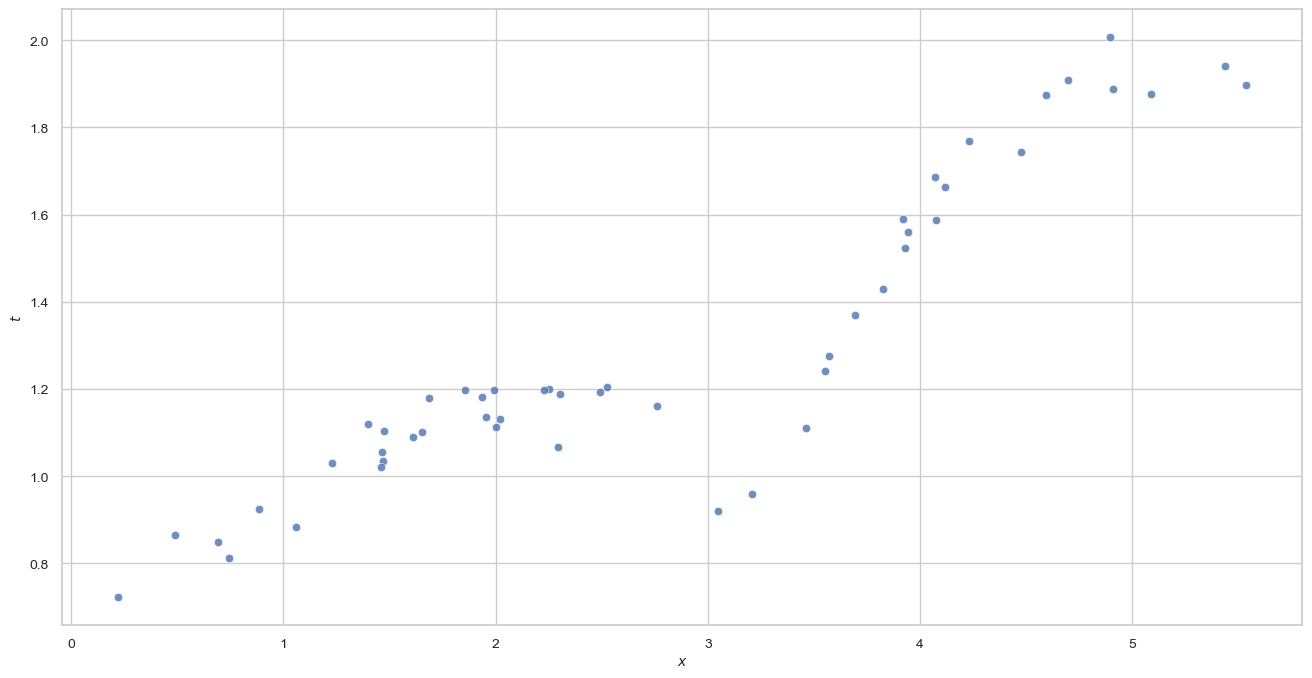

In [7]:
fig = plt.figure(figsize=(16,8))
ax = fig.gca()
sns.scatterplot(x=np.ravel(X), y=np.ravel(t), marker='o', alpha=.8, ax=ax)
plt.xlabel(u'$x$', fontsize=10)
plt.ylabel(u'$t$', fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

## Il prior

Il prior è una gaussiana isotropa con media nulla, $\mathcal{N}(\mathbf{0},\alpha^{-1}\mathbf{I})$: nessuna preferenza per il segno dei coefficienti, stessa incertezza in tutte le direzioni. La precisione del rumore è fissata a $\beta=9$, cioè una deviazione standard assunta di $1/3$, più grande di quella effettiva ($0.05$): il modello attribuisce al rumore anche lo scarto sistematico tra $f$ e una retta.

*Nota:* nella versione originale `alfa` era usato come **varianza** del prior, e nel calcolo del posterior la covarianza del prior veniva sommata a $\beta\boldsymbol\Phi^T\boldsymbol\Phi$ invece della sua inversa. Il codice è stato corretto: `alfa` è ora la precisione, come nelle note (il valore $\alpha=2$ è quello dell'esempio delle note), e il posterior usa $\boldsymbol\Sigma_0^{-1}$.

In [8]:
# precisione del prior: p(w) = N(0, alfa^{-1} I)
alfa=2
# parametri del prior
mu_prior=np.zeros(2)
sigma_prior=np.eye(2)/alfa

# parametro per la verosimiglianza
beta=9

# distribuzione a priori dei parametri
func=np.vectorize(lambda x,y:st.multivariate_normal.pdf([x,y],mu_prior,sigma_prior))

## Visualizzazione del prior

Calcoliamo la densità del prior su una griglia del piano $(w_0,w_1)$ e campioniamo $10$ vettori di parametri, cioè $10$ rette, dal prior.

In [9]:
# definisce un array di 500 valori distribuiti lineramente tra -1 e 1 per la dimensione x
x = np.linspace(-1, 1, 200)
# definisce un array di 500 valori distribuiti lineramente tra -1 e 1 per la dimensione y
y = np.linspace(-1, 1, 200)
# definisce una griglia bidimensionale a partire dagli array per x e y
# in X i valori delle ascisse dei punti sulla griglia, in Y i valori delle ordinate
XX,YY = np.meshgrid(x, y)
# calcola in Z i valori della funzione su tutti i punti della griglia
Z=func(XX,YY)

xx=np.linspace(min(X),max(X),500)
Phixx=vphi(xx,n_coeff)

sample_prior=np.random.multivariate_normal(mu_prior, sigma_prior, 10)

A sinistra, la densità del prior: una "collina" circolare centrata nell'origine. A destra, le rette corrispondenti ai parametri campionati: hanno pendenze e intercette arbitrarie, perché prima di osservare i dati qualunque retta con coefficienti non troppo grandi è plausibile.

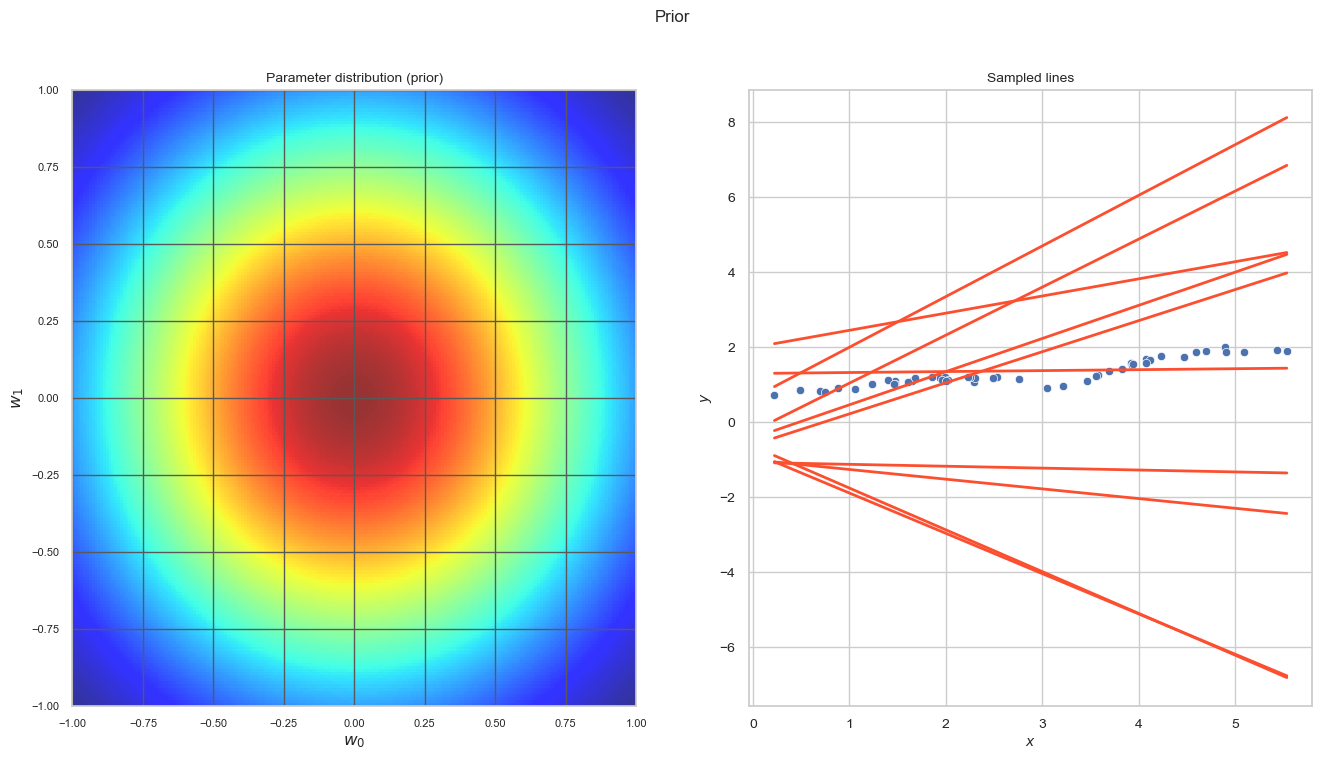

In [10]:
fig = plt.figure(figsize=(16,8))
ax=plt.subplot(1,2,1)
imshow_handle = ax.imshow(Z, origin='lower', extent=(x.min(),x.max(), y.min(), y.max()), aspect='auto', alpha=.8)
ax.set_xlabel('$w_0$', fontsize=12)
ax.set_ylabel('$w_1$', fontsize=12)
plt.xlim(-1,1)
plt.ylim(-1,1)
ax.set_title('Parameter distribution (prior)')
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
ax.grid(visible=True, which='both', color='0.35')
ax=plt.subplot(1,2,2)
ax.set_title('Sampled lines')
sns.scatterplot(x=np.ravel(X), y=np.ravel(t), marker='o', alpha=1, ax=ax)
plt.xlabel('$x$', fontsize=10)
plt.ylabel('$y$', fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
for w in sample_prior:
    yy=Phixx.dot(w)
    sns.lineplot(x=np.ravel(xx), y=np.ravel(yy), color=colors[1], ax=ax)
plt.suptitle(u'Prior')
plt.show()

## Il posterior dopo 5 elementi

Calcoliamo il posterior usando solo i primi $l=5$ elementi (in rosso nel grafico di destra), e campioniamo $10$ rette da esso. Il quadratino blu indica la media del posterior.

La densità non è più circolare: è concentrata lungo una direzione. I pochi dati osservati vincolano bene una combinazione dei due parametri, la "posizione" della retta nella regione dei punti, ma lasciano incerta un'altra combinazione: rette diverse, che passano tutte vicino ai punti osservati, differiscono soprattutto lontano da essi. Le rette campionate sono infatti tutte vicine ai punti rossi e si allargano a ventaglio altrove.

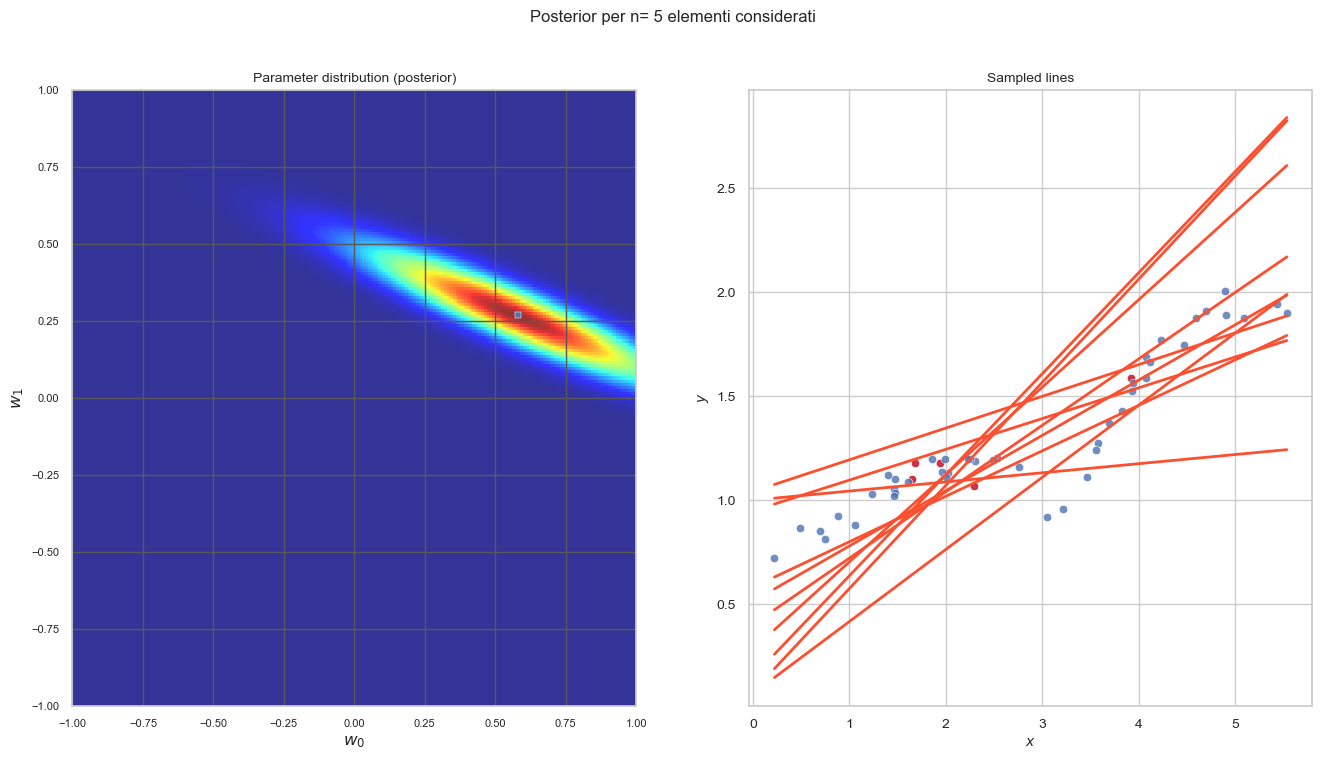

In [11]:
l = 5
X_t, t_t = Phi[:l,:], t[:l]
sigma_post = np.linalg.inv(np.linalg.inv(sigma_prior)+beta*np.dot(X_t.T,X_t))
mu_post=beta*sigma_post.dot(X_t.T.dot(t_t)).flatten()
sdx = np.sqrt(sigma_post[0,0])
sdy = np.sqrt(sigma_post[1,1])
    
func=np.vectorize(lambda x,y:st.multivariate_normal.pdf([x,y],mu_post,sigma_post))
x = np.linspace(-1, 1, 200)
y = np.linspace(-1, 1, 200)
XX,YY = np.meshgrid(x, y)
Z=func(XX,YY)
    
sample_post=np.random.multivariate_normal(mu_post, sigma_post, 10)
    
fig = plt.figure(figsize=(16,8))
ax=plt.subplot(1,2,1)
ax.set_aspect(1)
sns.scatterplot(x=np.ravel(mu_post[0]), y=np.ravel(mu_post[1]), s=20, marker='s', color='b', ax=ax)
imshow_handle = ax.imshow(Z, origin='lower', extent=(x.min(),x.max(), y.min(), y.max()), aspect='auto', alpha=.8)
ax.set_xlabel('$w_0$', fontsize=12)
ax.set_ylabel('$w_1$', fontsize=12)
ax.set_title('Parameter distribution (posterior)')
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
ax.grid(visible=True, which='both', color='0.35')
ax=plt.subplot(1,2,2)
ax.set_title('Sampled lines')
sns.scatterplot(x=np.ravel(X[:l]), y=np.ravel(t[:l]), marker='o', alpha=.8, color=colors[7], ax=ax)
sns.scatterplot(x=np.ravel(X[l:]), y=np.ravel(t[l:]), marker='o', alpha=.8, ax=ax)
plt.xlabel(u'$x$', fontsize=10)
plt.ylabel('$y$', fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
for w in sample_post:
    yy=Phixx.dot(w)
    sns.lineplot(x=np.ravel(xx), y=np.ravel(yy), color=colors[1], ax=ax)
plt.suptitle(u'Posterior per n={0:2d} elementi considerati'.format(l))
plt.show()

## Il posterior dopo 15 elementi

Con $l=15$ elementi il posterior è molto più concentrato: la precisione è aumentata del contributo $\beta\boldsymbol\phi(x_i)\boldsymbol\phi(x_i)^T$ di ogni nuovo elemento, e l'ellisse di incertezza si è ristretta. Le rette campionate sono ora molto simili tra loro. (Il codice ripete quello della cella precedente, con un diverso valore di `l`: si potrebbe raccoglierlo in una funzione.)

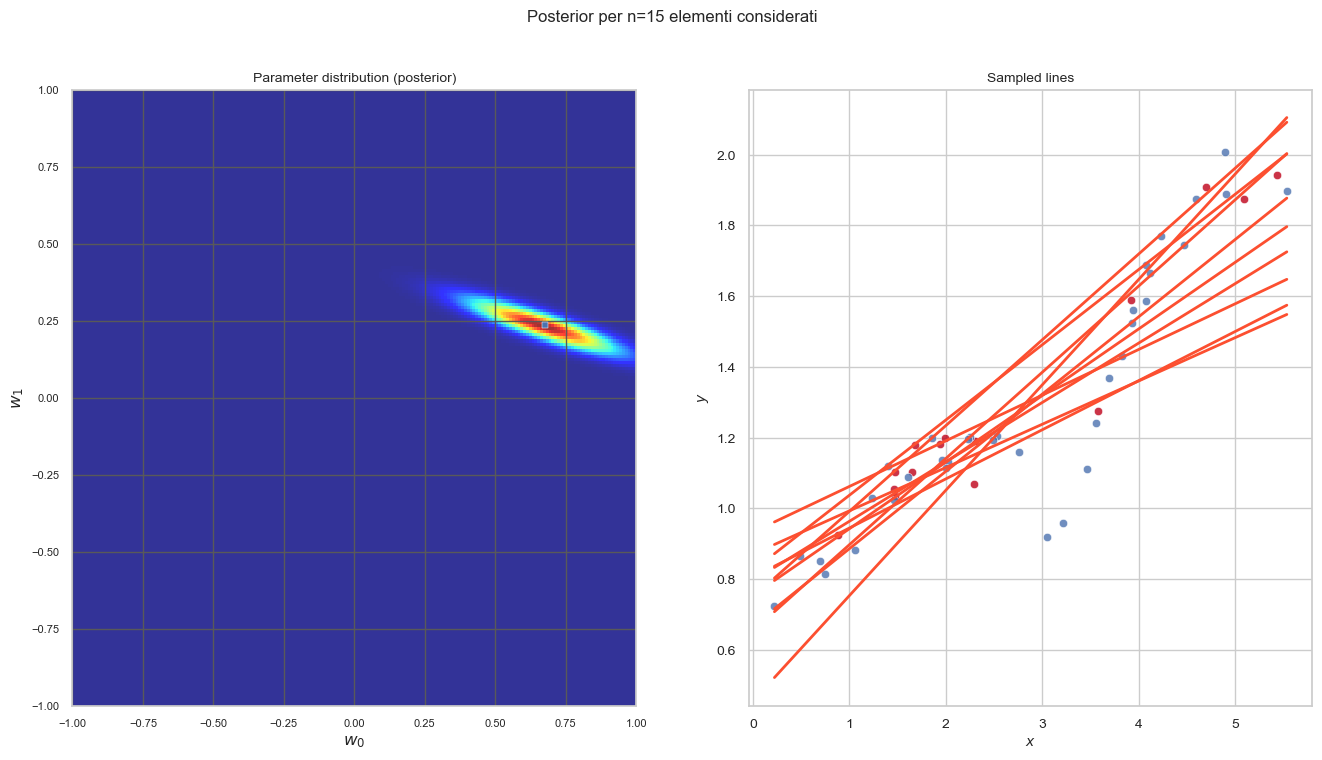

In [12]:
l = 15
X_t, t_t = Phi[:l,:], t[:l]
sigma_post = np.linalg.inv(np.linalg.inv(sigma_prior)+beta*np.dot(X_t.T,X_t))
mu_post=beta*sigma_post.dot(X_t.T.dot(t_t)).flatten()
sdx = np.sqrt(sigma_post[0,0])
sdy = np.sqrt(sigma_post[1,1])
    
func=np.vectorize(lambda x,y:st.multivariate_normal.pdf([x,y],mu_post,sigma_post))
x = np.linspace(-1, 1, 200)
y = np.linspace(-1, 1, 200)
XX,YY = np.meshgrid(x, y)
Z=func(XX,YY)
    
sample_post=np.random.multivariate_normal(mu_post, sigma_post, 10)
    
fig = plt.figure(figsize=(16,8))
ax=plt.subplot(1,2,1)
ax.set_aspect(1)
sns.scatterplot(x=np.ravel(mu_post[0]), y=np.ravel(mu_post[1]), s=20, marker='s', color='b', ax=ax)
imshow_handle = ax.imshow(Z, origin='lower', extent=(x.min(),x.max(), y.min(), y.max()), aspect='auto', alpha=.8)
ax.set_xlabel('$w_0$', fontsize=12)
ax.set_ylabel('$w_1$', fontsize=12)
ax.set_title('Parameter distribution (posterior)')
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
ax.grid(visible=True, which='both', color='0.35')
ax=plt.subplot(1,2,2)
ax.set_title('Sampled lines')
sns.scatterplot(x=np.ravel(X[:l]), y=np.ravel(t[:l]), marker='o', alpha=.8, color=colors[7], ax=ax)
sns.scatterplot(x=np.ravel(X[l:]), y=np.ravel(t[l:]), marker='o', alpha=.8, ax=ax)
plt.xlabel(u'$x$', fontsize=10)
plt.ylabel('$y$', fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
for w in sample_post:
    yy=Phixx.dot(w)
    sns.lineplot(x=np.ravel(xx), y=np.ravel(yy), color=colors[1], ax=ax)
plt.suptitle(u'Posterior per n={0:2d} elementi considerati'.format(l))
plt.show()

## Il posterior dopo 30 elementi

Con $l=30$ elementi il posterior è quasi un punto, e le rette campionate sono pressoché indistinguibili: l'incertezza **epistemica** sui parametri è quasi scomparsa. Resta naturalmente il rumore dei dati, e resta l'errore di approssimazione dovuto al fatto che $f$ non è una retta: il posterior si concentra attorno alla retta migliore *all'interno del modello*, non attorno a $f$. Come osservato nelle note, con abbastanza dati il posterior si concentra indipendentemente dal prior: provare a cambiare $\alpha$ mostra che il suo effetto è visibile con $5$ elementi e quasi nullo con $30$.

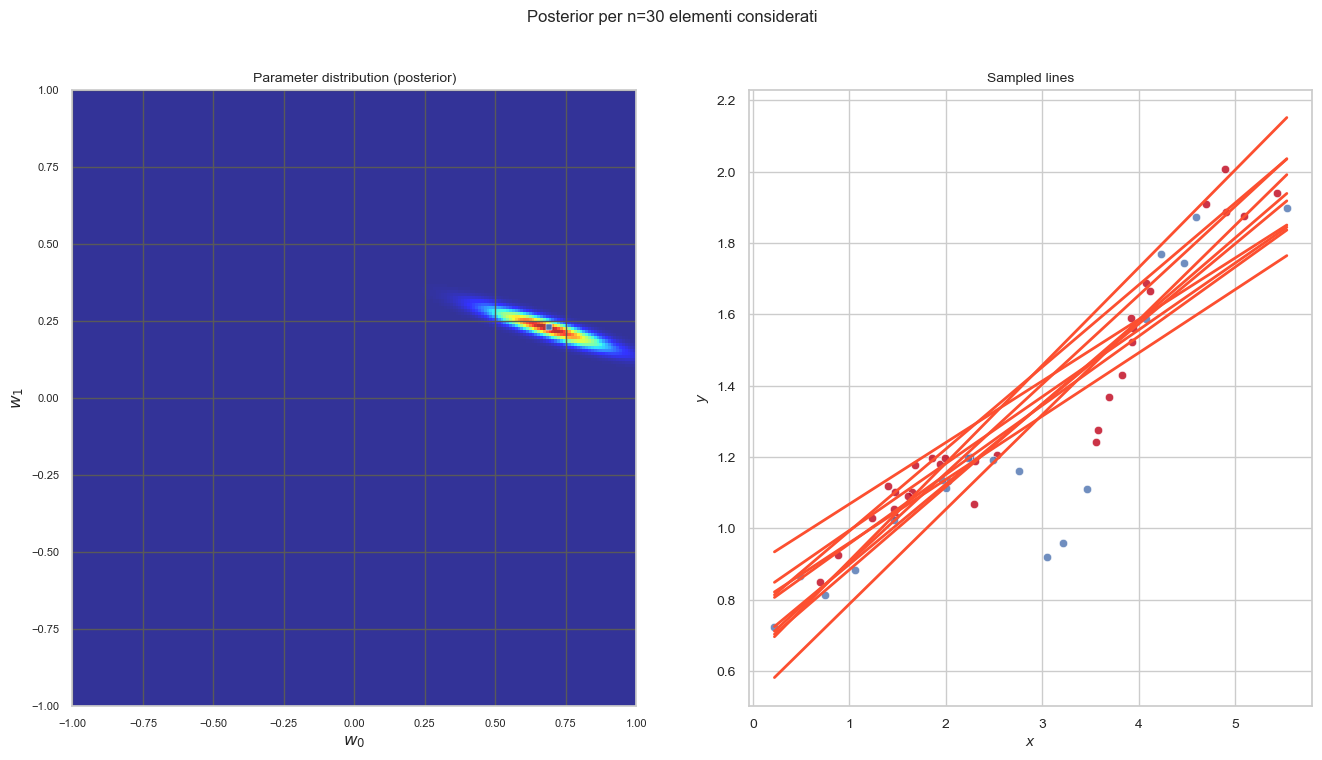

In [13]:
l = 30
X_t, t_t = Phi[:l,:], t[:l]
sigma_post = np.linalg.inv(np.linalg.inv(sigma_prior)+beta*np.dot(X_t.T,X_t))
mu_post=beta*sigma_post.dot(X_t.T.dot(t_t)).flatten()
sdx = np.sqrt(sigma_post[0,0])
sdy = np.sqrt(sigma_post[1,1])
    
func=np.vectorize(lambda x,y:st.multivariate_normal.pdf([x,y],mu_post,sigma_post))
x = np.linspace(-1, 1, 200)
y = np.linspace(-1, 1, 200)
XX,YY = np.meshgrid(x, y)
Z=func(XX,YY)
    
sample_post=np.random.multivariate_normal(mu_post, sigma_post, 10)
    
fig = plt.figure(figsize=(16,8))
ax=plt.subplot(1,2,1)
ax.set_aspect(1)
sns.scatterplot(x=np.ravel(mu_post[0]), y=np.ravel(mu_post[1]), s=20, marker='s', color='b', ax=ax)
imshow_handle = ax.imshow(Z, origin='lower', extent=(x.min(),x.max(), y.min(), y.max()), aspect='auto', alpha=.8)
ax.set_xlabel('$w_0$', fontsize=12)
ax.set_ylabel('$w_1$', fontsize=12)
ax.set_title('Parameter distribution (posterior)')
ax.xaxis.set_tick_params(labelsize=8)
ax.yaxis.set_tick_params(labelsize=8)
ax.grid(visible=True, which='both', color='0.35')
ax=plt.subplot(1,2,2)
ax.set_title('Sampled lines')
sns.scatterplot(x=np.ravel(X[:l]), y=np.ravel(t[:l]), marker='o', alpha=.8, color=colors[7], ax=ax)
sns.scatterplot(x=np.ravel(X[l:]), y=np.ravel(t[l:]), marker='o', alpha=.8, ax=ax)
plt.xlabel(u'$x$', fontsize=10)
plt.ylabel('$y$', fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
for w in sample_post:
    yy=Phixx.dot(w)
    sns.lineplot(x=np.ravel(xx), y=np.ravel(yy), color=colors[1], ax=ax)
plt.suptitle(u'Posterior per n={0:2d} elementi considerati'.format(l))
plt.show()